In [ ]:
import math, hashlib, random, time, warnings
from dataclasses import dataclass, field, replace
from typing import Optional, List, Dict, Tuple
import numpy as np
import pandas as pd
import simpy
import matplotlib.pyplot as plt
from scipy import stats

In [11]:
RISKS = ("low", "medium", "high")
RTYPES = ("routine_validation", "resource_allocation", "exception_escalation")

@dataclass(frozen=True)
class Params:
    # supervisor workload model (Eq. 1-3, 5-6)
    lam_rec: float = 0.02
    omega_int: float = 0.15
    delta_ref: float = 15.0
    delta_res: float = 0.10
    kappa: float = 0.30
    theta_rest: float = 0.30
    theta_busy: float = 0.70          # evaluation only
    # gatekeeper
    eps_crit: float = 22.5            # paper: 7.5 ; notebook: 22.5
    T_d: float = 30.0
    tau_def: float = 90.0             # adaptive release: deferral timeout
    d_theta: float = 0.25             # adaptive release: threshold relaxation
    theta_max: float = 0.60
    # organisation / arrivals
    n_agents: int = 5
    n_resources: int = 5
    critical_resources: tuple = ("workflow_0",)     # P(c=1) = 0.2
    p_risk: tuple = (0.60, 0.30, 0.10)
    insp_mean: float = 15.0
    insp_std: float = 5.0
    win_high: tuple = (30.0, 120.0)
    win_other: tuple = (60.0, 300.0)
    burst_extra: float = 0.5
    # cost model (Eq. 8)
    c_int: float = 1.0
    c_dig: float = 1.0
    c_over: float = 20.0
    p_err: float = 0.02
    C_err: float = 5.0
    C_err_crit: float = 25.0
    C_miss: tuple = (1.0, 5.0, 20.0)

@dataclass(frozen=True)
class Policy:
    name: str
    kind: str                 # fcfs | edf | horvitz | static | gk
    auto: bool = True
    batch: bool = True
    gate: bool = True
    escalate: bool = True
    adaptive: bool = False

POLICIES: Dict[str, Policy] = {p.name: p for p in [
    Policy("FCFS", "fcfs"), Policy("EDF", "edf"),
    Policy("Horvitz", "horvitz"), Policy("StaticFilter", "static"),
    Policy("Gatekeeper", "gk"),                       # paper version
    Policy("GK_Adaptive", "gk", adaptive=True),       # + adaptive release
    # ablations of the full method (GK_Adaptive)
    Policy("GK_noAuto", "gk", auto=False, adaptive=True),
    Policy("GK_noBatch", "gk", batch=False, adaptive=True),
    Policy("GK_noGate", "gk", gate=False),
    Policy("GK_noEsc", "gk", escalate=False, adaptive=True),
]}
MAIN = ["FCFS", "EDF", "Horvitz", "StaticFilter", "Gatekeeper", "GK_Adaptive"]
ABL = ["GK_Adaptive", "GK_noAuto", "GK_noBatch", "GK_noGate", "GK_noEsc"]
P0 = Params()

In [2]:
#journal d’audit infalsifiable
def decide(pol: Policy, p: Params, risk: str, crit: bool, slack: float):
    """Admission rule D(x,t) of Eq. (4). Deterministic: depends only on (risk, crit, slack)."""
    if risk == "high":
        return "M_int", "HIGH_RISK"
    if pol.escalate and slack <= p.eps_crit:
        return "M_int", "DEADLINE_CRITICAL"
    if pol.auto and risk == "low" and not crit:
        return "M_auto", "LOW_RISK_NONCRIT"
    if not pol.batch:
        return "M_int", "BATCHING_DISABLED"
    if risk == "medium":
        return "M_batch", "MEDIUM_RISK"
    return "M_batch", ("LOW_RISK_CRITICAL_RESOURCE" if crit else "LOW_RISK_AUTONOMY_DISABLED")

class AuditTrail:
    GENESIS = "0" * 64
    def __init__(self, seed=0):
        self.logs: List[dict] = []
        self.last = self.GENESIS
        self._rng = random.Random(seed)      # reproducible UUIDs

    @staticmethod
    def _payload(e):
        return (f"{e['uuid']}|{e['t']:.4f}|{e['rtype']}|{e['risk']}|{e['crit']}|"
                f"{e['slack']:.4f}|{e['L']:.4f}|{e['mode']}|{e['reason']}|{e['prev']}")

    def append(self, t, req, slack, L, mode, reason):
        e = dict(uuid=str(random.Random(self._rng.getrandbits(64)).getrandbits(128)),
                 t=t, rid=req.rid, rtype=req.rtype, risk=req.risk, crit=req.crit,
                 slack=slack, L=L, mode=mode, reason=reason, prev=self.last)
        e["hash"] = hashlib.sha256(self._payload(e).encode()).hexdigest()   # full SHA-256
        self.logs.append(e); self.last = e["hash"]

    @classmethod
    def verify_logs(cls, logs) -> Tuple[bool, Optional[int]]:
        prev = cls.GENESIS
        for i, e in enumerate(logs):
            if e["prev"] != prev or hashlib.sha256(cls._payload(e).encode()).hexdigest() != e["hash"]:
                return False, i
            prev = e["hash"]
        return True, None

    def verify(self): return self.verify_logs(self.logs)

    def recompute_rules(self, pol: Policy, p: Params) -> float:
        """Fraction of records whose logged mode is reproduced from (risk, crit, slack) alone."""
        ok = n = 0
        for e in self.logs:
            n += 1
            if e["mode"] == "int_escalated":
                ok += (e["slack"] <= p.eps_crit + 1e-6)
            else:
                ok += (decide(pol, p, e["risk"], e["crit"], e["slack"])[0] == e["mode"])
        return ok / max(n, 1)

def tamper_test(audit: AuditTrail, n_trials=200, seed=0):
    """Alter one field of one random record; report detection rate and localisation accuracy."""
    rng = random.Random(seed); det = loc = 0
    for _ in range(n_trials):
        logs = [dict(e) for e in audit.logs]
        i = rng.randrange(len(logs))
        logs[i]["mode"] = "M_auto" if logs[i]["mode"] != "M_auto" else "M_int"
        ok, first = AuditTrail.verify_logs(logs)
        det += (not ok); loc += (first == i)
    return det / n_trials, loc / n_trials

In [7]:
#modèle SimPy
class Supervisor:
    """Cognitive workload L_h(t): exponential recovery (Eq.1) + shocks (Eq.3/6).
    Time with L_h >= theta_busy is integrated analytically (no sampling error)."""
    def __init__(self, p: Params, warmup: float, trace=False):
        self.p, self.warmup = p, warmup
        self.L, self.t_last = 0.0, 0.0
        self.over_time = 0.0
        self.trace = [] if trace else None

    def level(self, now):
        dt = now - self.t_last
        if dt > 0:
            L0, th = self.L, self.p.theta_busy
            if L0 > th:
                d = min(dt, math.log(L0 / th) / self.p.lam_rec)
                a, b = max(self.t_last, self.warmup), self.t_last + d
                if b > a: self.over_time += b - a
            self.L = L0 * math.exp(-self.p.lam_rec * dt)
            self.t_last = now
        return self.L

    def expose(self, now, duration):
        L = self.level(now)
        self.L = min(1.0, L + self.p.omega_int * duration / self.p.delta_ref + self.p.delta_res)
        if self.trace is not None: self.trace.append((now, self.L))

@dataclass
class Request:
    rid: int; agent: int; rtype: str; risk: str; res: int; crit: bool
    t_arr: float; deadline: float; delta: float
    mode: str = ""; t_start: Optional[float] = None; t_done: Optional[float] = None
    in_buffer: bool = False; escalated: bool = False; via_digest: bool = False

class Sim:
    def __init__(self, pol: Policy, lam: float, seed: int, p: Params,
                 horizon: float, warmup: float, audit: bool, trace: bool):
        self.pol, self.lam, self.p, self.H, self.W = pol, lam, p, horizon, warmup
        self.env = simpy.Environment()
        self.server = simpy.PriorityResource(self.env, capacity=1)   # unit-capacity, non-preemptive
        self.sup = Supervisor(p, warmup, trace)
        self.rng = np.random.default_rng(seed)       # ONLY the generator draws random numbers (CRN)
        v = (p.insp_std / p.insp_mean) ** 2
        self.mu, self.sig = math.log(p.insp_mean) - 0.5 * math.log(1 + v), math.sqrt(math.log(1 + v))
        self.reqs: List[Request] = []; self.buffer: List[Request] = []; self.held: List[Request] = []
        self.n_int = self.n_dig = 0
        self.in_server = 0; self.n_pending = 0
        self.audit = AuditTrail(seed) if (audit and pol.kind == "gk") else None
        self.qtrace = [(0.0, 0)] if trace else None
        self.digests: List[tuple] = []
        self.env.process(self.arrivals())
        if pol.kind == "gk" and pol.batch: self.env.process(self.digest_loop())
        if pol.kind == "horvitz": self.env.process(self.horvitz_loop())

    # ---------- arrival process: compound Poisson, burst rate lam/1.5, size 1+Poisson(0.5) ----------
    def arrivals(self):
        n = 0
        while True:
            yield self.env.timeout(self.rng.exponential(1.5 / self.lam))
            for _ in range(1 + self.rng.poisson(self.p.burst_extra)):
                n += 1; self.submit(self.new_request(n))

    def new_request(self, rid):
        r, p = self.rng, self.p
        risk = RISKS[r.choice(3, p=p.p_risk)]
        res = int(r.integers(p.n_resources)); rtype = RTYPES[int(r.integers(3))]
        agent = int(r.integers(p.n_agents)); delta = float(r.lognormal(self.mu, self.sig))
        win = float(r.uniform(*(p.win_high if risk == "high" else p.win_other)))
        now = self.env.now
        return Request(rid, agent, rtype, risk, res, f"workflow_{res}" in p.critical_resources,
                       now, now + win, delta)

    # ---------- bookkeeping ----------
    def _pend(self, d):
        self.n_pending += d
        if self.qtrace is not None: self.qtrace.append((self.env.now, self.n_pending))

    def _dispatch(self, r, prio):
        self.in_server += 1
        self.env.process(self.serve(r, prio))

    def _auto(self, r):
        r.mode, r.t_done = "M_auto", self.env.now

    # ---------- admission ----------
    def submit(self, r: Request):
        self.reqs.append(r); k = self.pol.kind
        if k == "fcfs":
            r.mode = "M_int"; self._pend(+1); self._dispatch(r, 0.0)
        elif k == "edf":
            r.mode = "M_int"; self._pend(+1); self._dispatch(r, r.deadline)
        elif k == "static":
            if r.risk == "low": self._auto(r)      # all low-risk requests, critical resources included
            #if r.risk == "low" and not r.crit: self._auto(r)
            else: r.mode = "M_int"; self._pend(+1); self._dispatch(r, r.deadline)
        elif k == "horvitz":
            r.mode = "M_int"; self.held.append(r); self._pend(+1)
        else:
            now = self.env.now; slack = r.deadline - now
            mode, reason = decide(self.pol, self.p, r.risk, r.crit, slack)
            if self.audit: self.audit.append(now, r, slack, self.sup.level(now), mode, reason)
            if mode == "M_auto": self._auto(r)
            elif mode == "M_int": r.mode = "M_int"; self._pend(+1); self._dispatch(r, 0.0)
            else:
                r.mode, r.in_buffer = "M_batch", True
                self.buffer.append(r); self._pend(+1)
                if self.pol.escalate: self.env.process(self.watch(r))

    def watch(self, r):
        """Exact deadline escalation: fires when slack reaches eps_crit (no polling)."""
        yield self.env.timeout(max(0.0, r.deadline - self.p.eps_crit - self.env.now))
        if r.in_buffer:
            self.buffer.remove(r); r.in_buffer = False; r.escalated = True; r.mode = "int_escalated"
            if self.audit:
                now = self.env.now
                self.audit.append(now, r, r.deadline - now, self.sup.level(now),
                                  "int_escalated", "DEADLINE_ESCALATION")
            self._dispatch(r, 0.0)

    # ---------- service (priority 0 = interruptions, 1 = digests) ----------
    def serve(self, r, prio):
        with self.server.request(priority=prio) as rq:
            yield rq
            r.t_start = self.env.now
            if r.t_start >= self.W: self.n_int += 1
            self.sup.expose(self.env.now, r.delta)
            yield self.env.timeout(r.delta)
            r.t_done = self.env.now
        self.in_server -= 1; self._pend(-1)

    def serve_digest(self, batch):
        with self.server.request(priority=1) as rq:
            yield rq
            t0 = self.env.now
            dur = float(np.mean([r.delta for r in batch])) * (1 + self.p.kappa * (len(batch) - 1))   # Eq.5
            if t0 >= self.W: self.n_dig += 1
            self.sup.expose(t0, dur)                                                                   # Eq.6
            yield self.env.timeout(dur)
            for r in batch: r.t_start, r.t_done, r.via_digest = t0, self.env.now, True
        self._pend(-len(batch))

    def release_threshold(self):
        p = self.p
        if self.pol.adaptive:
            age = self.env.now - min(r.t_arr for r in self.buffer)
            if age > p.tau_def: return min(p.theta_max, p.theta_rest + p.d_theta)
        return p.theta_rest

    def digest_loop(self):
        while True:
            yield self.env.timeout(self.p.T_d)
            if not self.buffer: continue
            L = self.sup.level(self.env.now)
            if (not self.pol.gate) or L <= self.release_threshold():
                batch, self.buffer = self.buffer, []
                for r in batch: r.in_buffer = False
                self.digests.append((self.env.now, len(batch), L > self.p.theta_rest))
                self.env.process(self.serve_digest(batch))

    # ---------- Horvitz-style bounded deferral baseline ----------
    def horvitz_loop(self):
        while True:
            yield self.env.timeout(1.0)
            now = self.env.now
            for r in sorted(self.held, key=lambda x: x.deadline):
                if now >= r.t_arr + 0.5 * (r.deadline - r.t_arr):
                    self.held.remove(r); self._dispatch(r, 0.0)
            if self.held and self.in_server == 0 and self.sup.level(now) <= self.p.theta_rest:
                r = min(self.held, key=lambda x: x.deadline)
                self.held.remove(r); self._dispatch(r, 0.0)

    # ---------- metrics ----------
    def metrics(self):
        p, H, W = self.p, self.H, self.W
        hrs = (H - W) / 3600.0
        sc = [r for r in self.reqs if r.t_arr >= W and r.deadline <= H]          # scored set
        met = lambda r: r.t_done is not None and r.t_done <= r.deadline          # unresolved = missed
        hr = [r for r in sc if r.risk == "high"]
        lat = np.array([(r.t_done if r.t_done is not None else H) - r.t_arr for r in hr])
        win = [r for r in self.reqs if r.t_arr >= W]
        A = sum(1 for r in win if r.mode == "M_auto" and not r.crit) / hrs
        Ac = sum(1 for r in win if r.mode == "M_auto" and r.crit) / hrs
        miss = [sum(1 for r in sc if r.risk == s and not met(r)) / hrs for s in RISKS]
        s_busy = self.sup.over_time / (H - W)
        I_int, I_dig = self.n_int / hrs, self.n_dig / hrs
        J_dis = p.c_int * I_int + p.c_dig * I_dig
        J_over = p.c_over * s_busy
        err_base = p.C_err * A + p.C_err_crit * Ac            # J_err = p_err * err_base
        J_miss = sum(c * m for c, m in zip(p.C_miss, miss))
        n_win = max(len(win), 1)
        share = lambda m: sum(1 for r in win if r.mode == m) / n_win
        return dict(
            I_int=I_int, I_dig=I_dig, dis=I_int + I_dig, sat=100 * s_busy,
            Wcrit=float(lat.mean()) if len(lat) else np.nan,
            P99=float(np.percentile(lat, 99)) if len(lat) else np.nan,
            phi=100 * np.mean([met(r) for r in sc]),
            thr=sum(1 for r in self.reqs if r.t_done is not None and W <= r.t_done <= H) / hrs,
            A=A, Acrit=Ac, m_low=miss[0], m_med=miss[1], m_high=miss[2],
            J_dis=J_dis, J_over=J_over, J_err=p.p_err * err_base, J_miss=J_miss, err_base=err_base,
            J=J_dis + J_over + p.p_err * err_base + J_miss,
            sh_auto=share("M_auto"), sh_batch=share("M_batch"), sh_int=share("M_int"), sh_esc=share("int_escalated"),
            n_scored=len(sc))

def run_sim(policy, lam, seed, p: Params = P0, horizon=7200.0, warmup=600.0, audit=False, detail=False):
    pol = POLICIES[policy] if isinstance(policy, str) else policy
    s = Sim(pol, lam, seed, p, horizon, warmup, audit, detail)
    s.env.run(until=horizon); s.sup.level(horizon)
    m = s.metrics()
    if not detail: return m
    W = warmup
    ex = dict(trace=s.sup.trace, qtrace=s.qtrace, digests=s.digests, audit=s.audit,
              defer=[r.t_done - r.t_arr for r in s.reqs if r.via_digest and r.t_arr >= W],
              digest_sizes=[n for (t, n, _) in s.digests if t >= W])
    return m, ex

In [8]:
#balayage, IC, tests statistiques
LAMS = [0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.08, 0.10]          # rho = 15*lam in [0.3, 1.5]
SEEDS = list(range(30)); TUNE_SEEDS = list(range(1000, 1010))     # disjoint: tuning vs evaluation
N_JOBS = 1                                                         # >1 requires joblib

def _job(a):
    pol, lam, seed, p = a
    m = run_sim(pol, lam, seed, p, audit=False)
    m.update(policy=pol if isinstance(pol, str) else pol.name, lam=lam, rho=round(15 * lam, 3), seed=seed); return m

def sweep(policies, lams=LAMS, seeds=SEEDS, p=P0, n_jobs=None):
    jobs = [(pol, lam, s, p) for lam in lams for pol in policies for s in seeds]
    n_jobs = n_jobs or N_JOBS
    if n_jobs > 1:
        from joblib import Parallel, delayed
        rows = Parallel(n_jobs=n_jobs)(delayed(_job)(j) for j in jobs)
    else:
        rows = [_job(j) for j in jobs]
    return pd.DataFrame(rows)

def ci95(x):
    x = np.asarray(x, float); n = len(x)
    return stats.t.ppf(0.975, n - 1) * x.std(ddof=1) / math.sqrt(n) if n > 1 else 0.0

def summarize(df, metrics):
    g = df.groupby(["policy", "rho"])[metrics]
    return g.mean(), g.agg(ci95)

def holm(pvals):
    order = np.argsort(pvals); m = len(pvals); adj = np.empty(m); run = 0.0
    for rank, i in enumerate(order):
        run = max(run, (m - rank) * pvals[i]); adj[i] = min(1.0, run)
    return adj

def paired_tests(df, target="GK_Adaptive", baselines=("FCFS", "EDF", "Horvitz", "StaticFilter", "Gatekeeper"), metric="J"):
    """Paired Wilcoxon on `metric` over replications (common random numbers), Holm-corrected."""
    rows = []
    for rho, d in df.groupby("rho"):
        a = d[d.policy == target].sort_values("seed")[metric].values
        for b in baselines:
            x = d[d.policy == b].sort_values("seed")[metric].values
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                try: pv = stats.wilcoxon(a, x).pvalue
                except ValueError: pv = 1.0                # all differences are zero
            if not np.isfinite(pv): pv = 1.0
            rows.append(dict(rho=rho, baseline=b, median_diff=np.median(a - x),
                             rel_change_pct=100 * (a.mean() - x.mean()) / x.mean(), p=pv))
    out = pd.DataFrame(rows); out["p_holm"] = holm(out.p.values)
    return out

def table3(df, lams=(0.04, 0.06, 0.08), policies=MAIN):
    cols = ["dis", "sat", "Wcrit", "phi", "J"]
    mean, _ = summarize(df, cols); t = {}
    for lam in lams:
        for c in cols: t[(f"rho={15*lam:.1f}", c)] = mean.xs(round(15 * lam, 3), level="rho")[c]
    return pd.DataFrame(t).loc[policies].round(1)

In [9]:
#figures
COL = {"FCFS": "#d62728", "EDF": "#ff7f0e", "Horvitz": "#9467bd", "StaticFilter": "#7f7f7f",
       "Gatekeeper": "#1f77b4", "GK_Adaptive": "#0b3d91", "GK_noAuto": "#2ca02c",
       "GK_noBatch": "#17becf", "GK_noGate": "#bcbd22", "GK_noEsc": "#e377c2"}
LS = {"Gatekeeper": "--", "GK_Adaptive": "-"}
LAB = dict(dis="Human disruptions / hour", sat="Time in overload (%)", Wcrit="Mean high-risk latency (s)",
           P99="99th-pct high-risk latency (s)", phi="Deadline adherence (%)", J="Expected cost / hour")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3, "font.size": 9})

def plot_grid(df, policies, metrics, logy=(), ncols=3, title=None, fname=None):
    mean, ci = summarize(df, metrics); n = len(metrics); nr = math.ceil(n / ncols)
    fig, axs = plt.subplots(nr, ncols, figsize=(4.2 * ncols, 3.1 * nr)); axs = np.atleast_1d(axs).ravel()
    for ax, m in zip(axs, metrics):
        for pol in policies:
            mu, c = mean.loc[pol][m], ci.loc[pol][m]
            ax.plot(mu.index, mu, LS.get(pol, "-"), color=COL[pol], label=pol, lw=1.6)
            ax.fill_between(mu.index, mu - c, mu + c, color=COL[pol], alpha=.2)
        ax.axvline(1, color="k", ls=":", lw=.8); ax.set_xlabel(r"Offered load $\rho = 15\lambda$"); ax.set_ylabel(LAB[m])
        if m in logy: ax.set_yscale("log")
    for ax in axs[n:]: ax.axis("off")
    axs[0].legend(fontsize=7)
    if title: fig.suptitle(title)
    fig.tight_layout()
    if fname: fig.savefig(fname, dpi=300)
    return fig

def fig_trace(lam=0.07, seed=0, pols=("FCFS", "StaticFilter", "Gatekeeper", "GK_Adaptive"), t0=0.0, span=900.0, p=P0):
    fig, (a1, a2) = plt.subplots(2, 1, figsize=(9, 5.5), sharex=True, gridspec_kw=dict(height_ratios=[2, 1]))
    for pol in pols:
        m, ex = run_sim(pol, lam, seed, p, detail=True)
        tr = np.array([(0.0, 0.0)] + ex["trace"]); tt = np.arange(600.0 + t0, 600.0 + t0 + span, 0.5)
        idx = np.searchsorted(tr[:, 0], tt, side="right") - 1
        L = tr[idx, 1] * np.exp(-p.lam_rec * (tt - tr[idx, 0]))
        a1.plot(tt - 600.0, L, color=COL[pol], lw=1, label=pol)
        q = np.array(ex["qtrace"]); qi = np.searchsorted(q[:, 0], tt, side="right") - 1
        a2.step(tt - 600.0, q[qi, 1], color=COL[pol], lw=1)
        if pol == "GK_Adaptive":
            for (t, n, relaxed) in ex["digests"]:
                if tt[0] <= t <= tt[-1]:
                    a1.plot(t - 600.0, 0.02, "^" if relaxed else "v", color="k" if relaxed else "grey", ms=5)
    a1.axhline(p.theta_busy, color="k", ls=":"); a1.axhline(p.theta_rest, color="k", ls=":")
    a1.text(2, p.theta_busy + .01, r"$\theta_{busy}$"); a1.text(2, p.theta_rest + .01, r"$\theta_{rest}$")
    a1.set_ylabel(r"Workload $L_h(t)$"); a1.legend(ncol=4, fontsize=7, loc="upper right")
    a2.set_ylabel("Pending requests"); a2.set_xlabel("Time after warm-up (s)")
    a1.set_title(rf"Cognitive workload and queue ($\lambda$={lam}, $\rho$={15*lam:.2f}); markers: digest releases (black = relaxed threshold)")
    fig.tight_layout(); return fig

def fig_mix(df, pols=("Gatekeeper", "GK_Adaptive")):
    fig, axs = plt.subplots(1, len(pols), figsize=(4.8 * len(pols), 3.4), sharey=True)
    for ax, pol in zip(np.atleast_1d(axs), pols):
        g = df[df.policy == pol].groupby("rho")[["sh_auto", "sh_batch", "sh_int", "sh_esc"]].mean()
        ax.stackplot(g.index, g.T.values * 100, labels=["Autonomous", "Digest", "Direct interruption", "Escalated"],
                     colors=["#6aa84f", "#6fa8dc", "#e06666", "#f6b26b"])
        ax.set_title(pol); ax.set_xlabel(r"Offered load $\rho$"); ax.set_ylim(0, 100)
    np.atleast_1d(axs)[0].set_ylabel("Share of requests (%)"); np.atleast_1d(axs)[0].legend(fontsize=7, loc="lower left")
    fig.tight_layout(); return fig

def fig_deferral(lams=(0.06, 0.10), pols=("Gatekeeper", "GK_Adaptive"), seeds=range(10), p=P0):
    fig, axs = plt.subplots(1, len(lams) + 1, figsize=(4.2 * (len(lams) + 1), 3.4))
    for ax, lam in zip(axs, lams):
        for pol in pols:
            d = np.sort(np.concatenate([run_sim(pol, lam, s, p, detail=True)[1]["defer"] for s in seeds]))
            ax.plot(d, np.arange(1, len(d) + 1) / len(d), color=COL[pol], ls=LS.get(pol, "-"), label=pol)
        ax.axvline(180, color="k", ls=":"); ax.set_xlabel("Deferral delay of digested requests (s)")
        ax.set_ylabel("ECDF"); ax.set_title(rf"$\rho$={15*lam:.1f}"); ax.legend(fontsize=7)
    for pol in pols:
        ds = np.concatenate([run_sim(pol, lams[-1], s, p, detail=True)[1]["digest_sizes"] for s in seeds])
        axs[-1].hist(ds, bins=np.arange(0.5, ds.max() + 1.5), alpha=.5, color=COL[pol], label=pol)
    axs[-1].set_xlabel("Digest size N"); axs[-1].set_ylabel("Count"); axs[-1].legend(fontsize=7)
    fig.tight_layout(); return fig

def fig_pareto(df, pols=MAIN):
    mean, _ = summarize(df, ["dis", "phi"]); fig, ax = plt.subplots(figsize=(5.2, 4))
    for pol in pols:
        g = mean.loc[pol]; ax.plot(g.dis, g.phi, marker="o", ms=3, color=COL[pol], label=pol, ls=LS.get(pol, "-"))
    ax.set_xlabel("Human disruptions / hour (lower is better)"); ax.set_ylabel("Deadline adherence (%) (higher is better)")
    ax.legend(fontsize=7); fig.tight_layout(); return fig

def tune_grid(lam, eps_list=(0, 7.5, 15, 22.5, 30, 45), tau_list=(30, 60, 90, 150, 300), seeds=TUNE_SEEDS):
    G = np.zeros((len(eps_list), len(tau_list)))
    for i, e in enumerate(eps_list):
        for j, t in enumerate(tau_list):
            q = replace(P0, eps_crit=e, tau_def=t)
            G[i, j] = np.mean([run_sim("GK_Adaptive", lam, s, q)["J"] for s in seeds])
    return G, eps_list, tau_list

def fig_tune(lams=(0.08, 0.10), **kw):
    fig, axs = plt.subplots(1, len(lams), figsize=(4.8 * len(lams), 3.8))
    for ax, lam in zip(np.atleast_1d(axs), lams):
        G, E, T = tune_grid(lam, **kw)
        im = ax.imshow(G, cmap="viridis_r", aspect="auto")
        ax.set_xticks(range(len(T)), T); ax.set_yticks(range(len(E)), E)
        ax.set_xlabel(r"Deferral timeout $\tau_{def}$ (s)"); ax.set_ylabel(r"Escalation margin $\epsilon_{crit}$ (s)")
        ax.set_title(rf"Mean cost J, $\rho$={15*lam:.1f}")
        for i in range(G.shape[0]):
            for j in range(G.shape[1]): ax.text(j, i, f"{G[i,j]:.0f}", ha="center", va="center", color="w", fontsize=7)
        fig.colorbar(im, ax=ax)
    fig.tight_layout(); return fig

def fig_cost(df, rho=1.2, pols=MAIN + ABL[1:]):
    d = df[np.isclose(df.rho, rho)].groupby("policy")[["J_dis", "J_over", "J_err", "J_miss", "err_base", "J"]].mean().loc[pols]
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
    bot = np.zeros(len(d))
    for c, lab, col in [("J_dis", "Human disruptions", "#1f77b4"), ("J_over", "Cognitive overload", "#ffbb78"),
                        ("J_err", "Autonomy errors", "#d62728"), ("J_miss", "Deadline misses", "#7f8c8d")]:
        a1.bar(d.index, d[c], bottom=bot, label=lab, color=col); bot += d[c].values
    a1.set_ylabel("Expected cost / hour"); a1.set_title(rf"Cost decomposition, $\rho$={rho}")
    a1.tick_params(axis="x", rotation=60); a1.legend(fontsize=7)
    pe = np.linspace(0, 0.6, 61)
    for pol in MAIN:
        r = d.loc[pol]; a2.plot(pe, r.J - r.J_err + pe * r.err_base, color=COL[pol], ls=LS.get(pol, "-"), label=pol)
    a2.axvline(P0.p_err, color="k", ls=":"); a2.set_xlabel(r"Autonomy error probability $p_{err}$")
    a2.set_ylabel("Expected cost / hour"); a2.set_title("Sensitivity to $p_{err}$"); a2.legend(fontsize=7)
    fig.tight_layout(); return fig

def fig_box(df, lams=(0.04, 0.06, 0.08), pols=MAIN):
    fig, axs = plt.subplots(1, len(lams), figsize=(4.4 * len(lams), 3.6), sharey=True)
    for ax, lam in zip(axs, lams):
        d = df[np.isclose(df.lam, lam)]
        ax.boxplot([d[d.policy == p].J.values for p in pols], tick_labels=pols, showfliers=False)
        ax.set_yscale("log"); ax.tick_params(axis="x", rotation=60); ax.set_title(rf"$\rho$={15*lam:.1f}")
    axs[0].set_ylabel("Expected cost / hour (per replication)"); fig.tight_layout(); return fig

             rho=0.6                          rho=0.9                     \
                 dis   sat Wcrit   phi      J     dis   sat  Wcrit   phi   
policy                                                                     
FCFS           142.6  23.8  43.3  95.5  213.7   213.1  65.4  127.1  68.6   
EDF            142.6  23.8  25.3  99.3  155.1   213.1  65.6   70.5  75.0   
Horvitz        142.6  16.8  52.9  93.2  218.8   212.8  63.0  140.1  51.7   
StaticFilter    58.6   1.1  19.1  99.9   75.4    88.5   4.1   21.0  99.8   
Gatekeeper      54.3   0.1  18.0  99.6   65.8    74.1   0.6   19.4  98.7   
GK_Adaptive     54.1   0.1  17.9  99.6   65.5    72.7   0.4   19.2  99.2   

                    rho=1.2                             
                  J     dis   sat  Wcrit   phi       J  
policy                                                  
FCFS          618.2   240.2  86.0  699.8   7.5  1383.1  
EDF           461.0   240.0  85.9  603.5   7.0  1360.6  
Horvitz       732.9   239.9  8

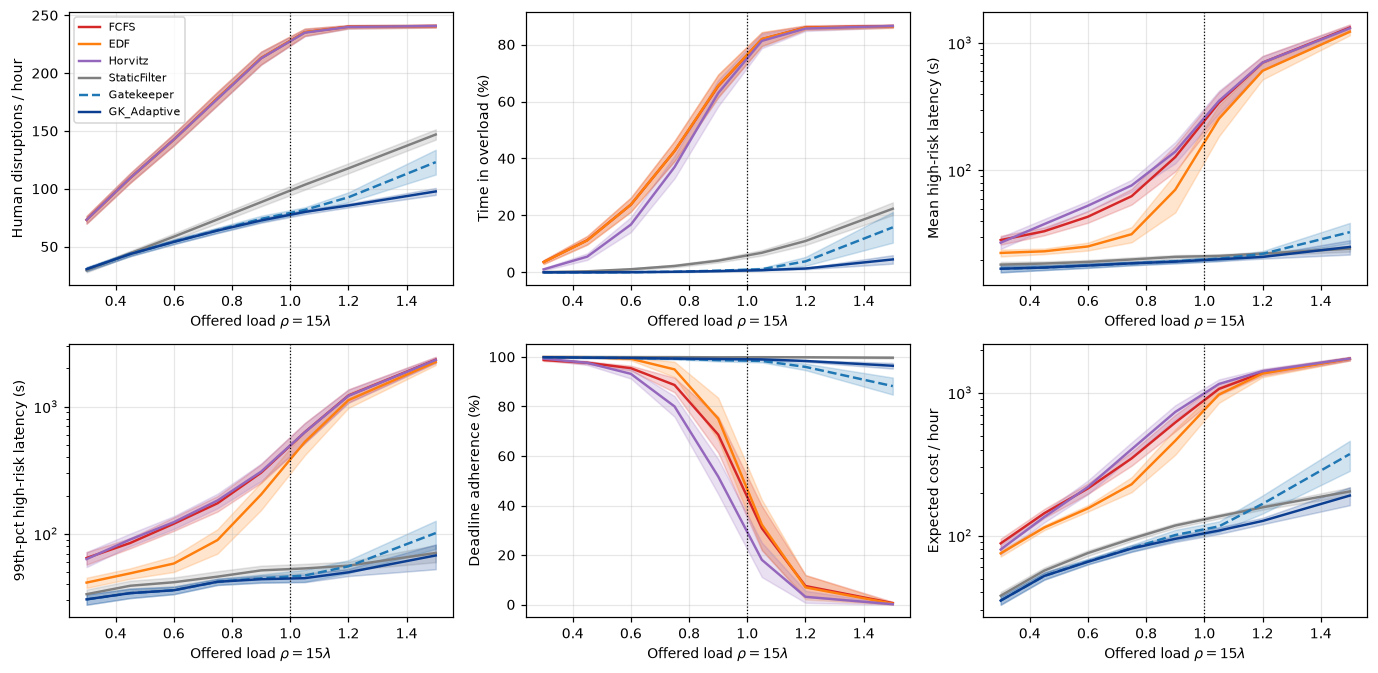

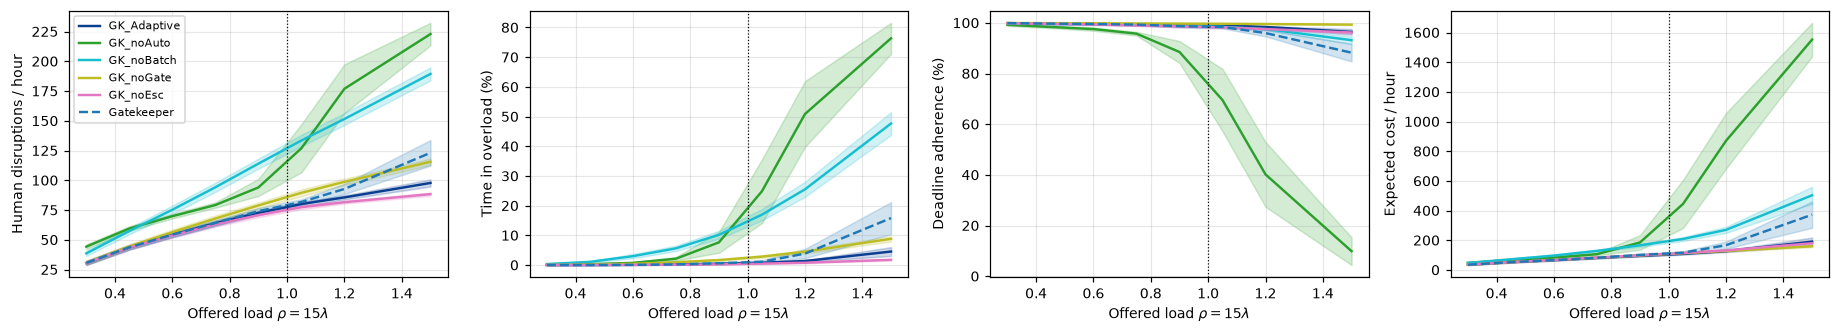

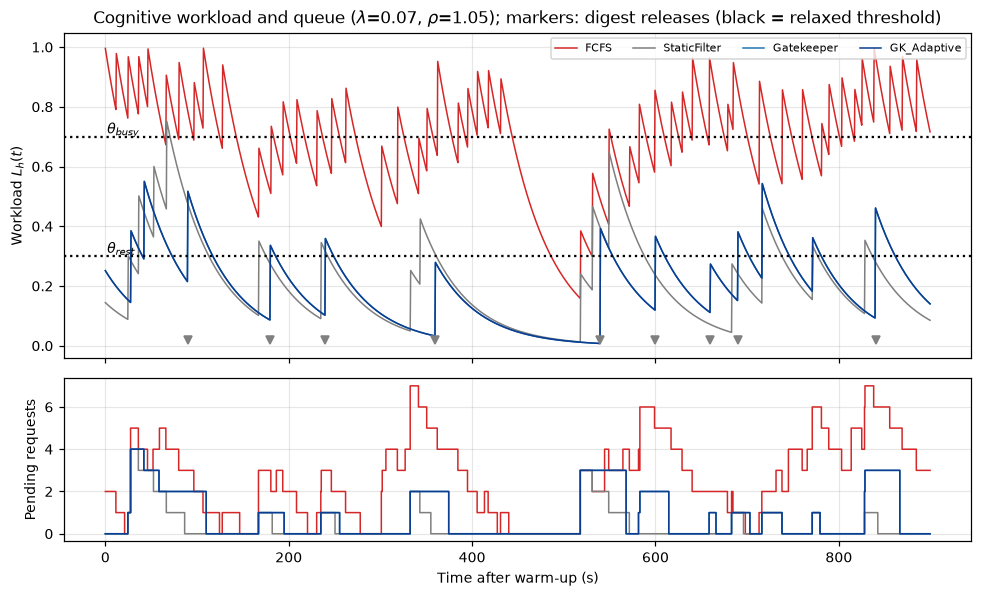

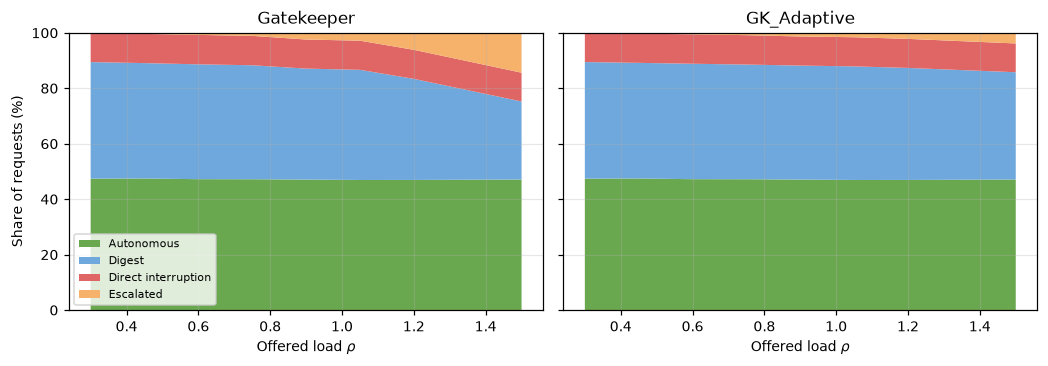

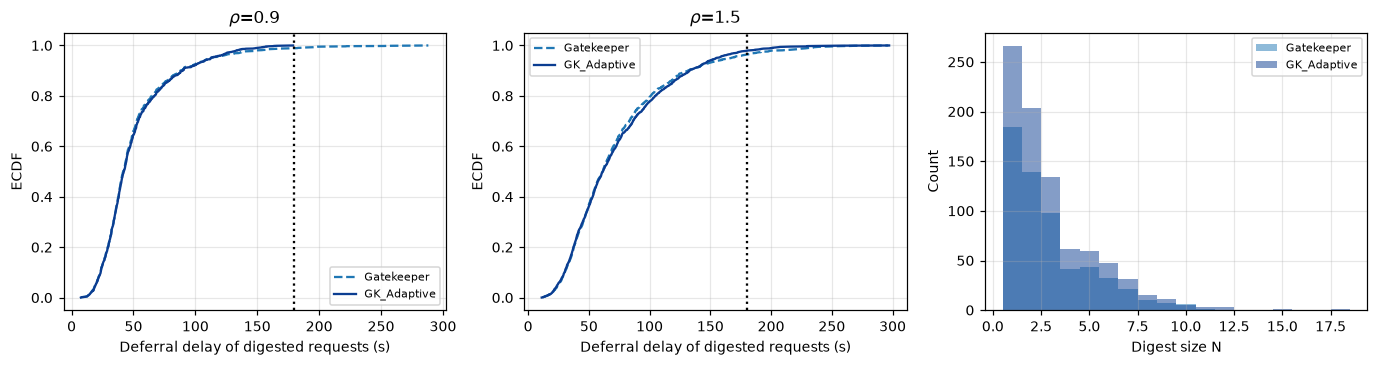

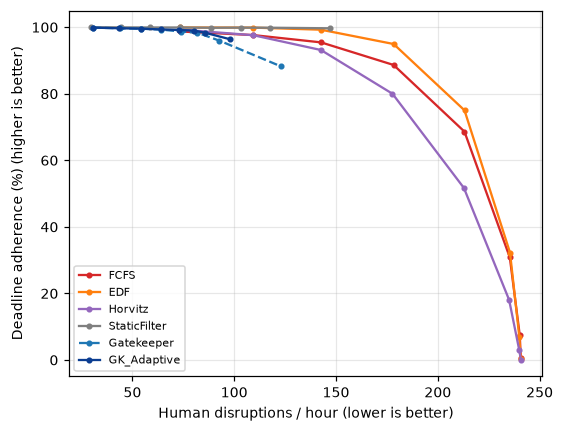

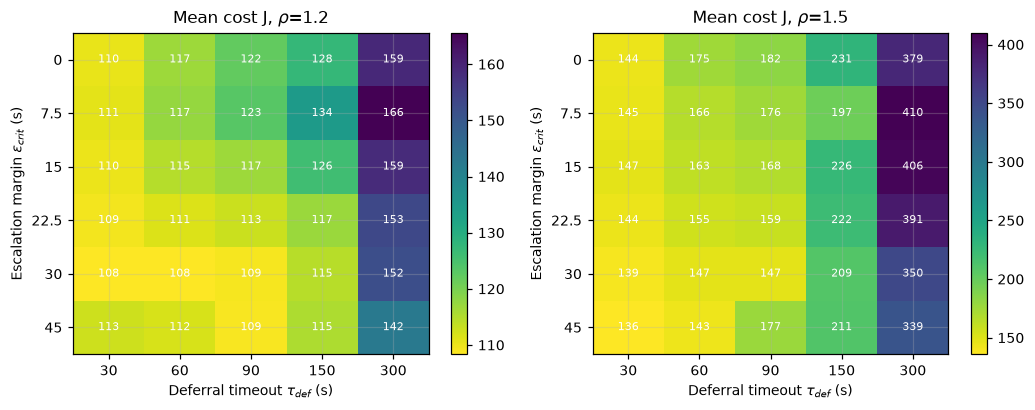

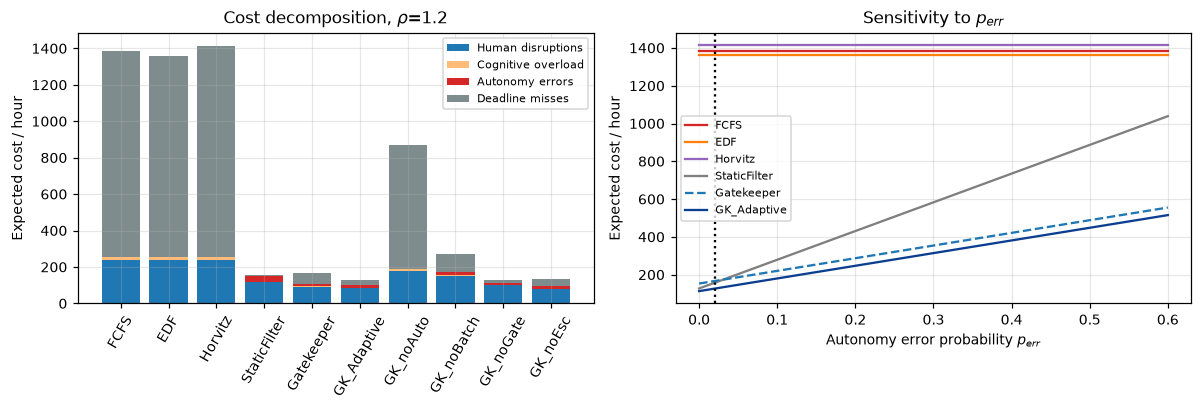

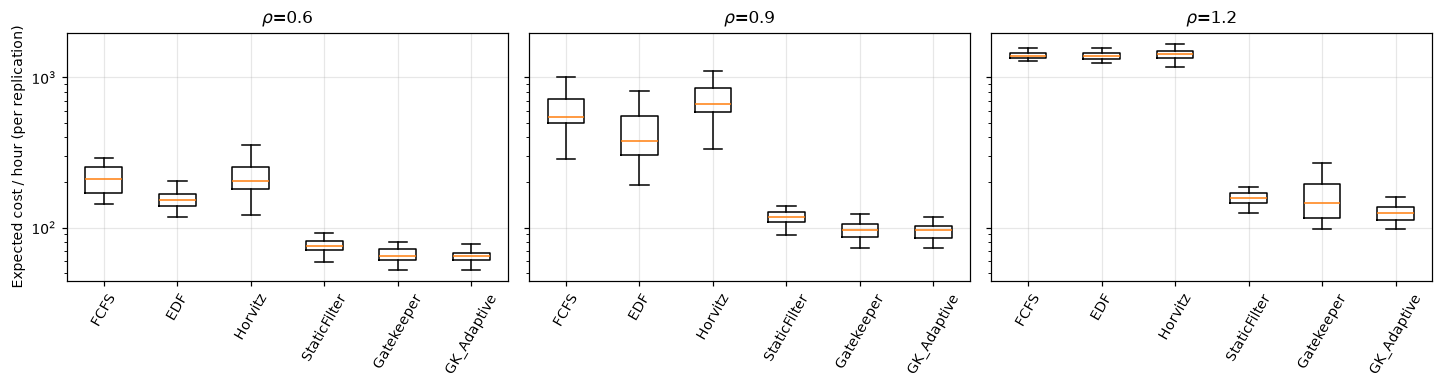

In [10]:
#exécution complète
N_JOBS = 4                                   # mettre 1 si joblib n'est pas installé
df = sweep(MAIN + ABL[1:], n_jobs=N_JOBS)    # 10 politiques x 8 charges x 30 graines = 2400 runs
df.to_csv("results.csv", index=False)

print(table3(df))                                                       # Tableau 3 (scénarios A, B, C)
pt = paired_tests(df); print(pt[pt.rho.isin([0.9, 1.2, 1.5])].round(4))  # Wilcoxon + Holm (GK_Adaptive vs autres)

plot_grid(df, MAIN, ["dis", "sat", "Wcrit", "P99", "phi", "J"], logy=("Wcrit", "P99", "J"),
          fname="fig_A_main_sweep.png")
plot_grid(df, ABL + ["Gatekeeper"], ["dis", "sat", "phi", "J"], ncols=4, fname="fig_ablation.png")
fig_trace().savefig("fig_B_trace.png", dpi=300)
fig_mix(df).savefig("fig_C_mix.png", dpi=300)
fig_deferral().savefig("fig_D_deferral.png", dpi=300)
fig_pareto(df).savefig("fig_E_pareto.png", dpi=300)
fig_tune().savefig("fig_F_sensitivity.png", dpi=300)   # graines de réglage 1000-1009, disjointes de l'évaluation
fig_cost(df).savefig("fig_G_cost.png", dpi=300)
fig_box(df).savefig("fig_H_boxplots.png", dpi=300)

# journal d'audit (§5.6) : chaîne valide, règle recalculée, détection d'altération
m, ex = run_sim("GK_Adaptive", 0.06, 0, audit=True, detail=True); a = ex["audit"]
print("records:", len(a.logs), "| chain valid:", a.verify()[0],
      "| rule recomputed:", a.recompute_rules(POLICIES["GK_Adaptive"], P0),
      "| tamper (detected, localised):", tamper_test(a))

# validation hors échantillon des hyperparamètres réglés (lus sur la Fig. F, testés sur les graines 0-29)
p_tuned = replace(P0, eps_crit=30.0, tau_def=30.0)
dt = sweep(["GK_Adaptive"], p=p_tuned); dt["policy"] = "GK_Tuned"
print(summarize(pd.concat([df[df.policy.isin(["StaticFilter", "GK_Adaptive"])], dt]), ["dis", "sat", "phi", "J"])[0].round(1))